In [1]:
import glob
for f in glob.glob("/kaggle/input/**/*", recursive=True):
    if "." in f.split("/")[-1]: print(f)

/kaggle/input/datasets/atharv0919/bioprior-v2/cell_features_v2.npz
/kaggle/input/datasets/atharv0919/bioprior-v2/drug_targets.csv
/kaggle/input/datasets/atharv0919/bioprior-v2/gdsc_targets.csv
/kaggle/input/datasets/atharv0919/bioprior-v2/sym2ent.json


In [2]:
!pip install -q rdkit
import os, re, glob, json, time, copy, subprocess
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
REPO = "/kaggle/working/bioprior"
if not os.path.exists(REPO):
    subprocess.run(["git","clone","https://github.com/raveena2309/bioprior.git",REPO], check=True)
P  = REPO + "/data/processed/"
IN = os.path.dirname(glob.glob("/kaggle/input/**/cell_features_v2.npz", recursive=True)[0]) + "/"
OUT = "/kaggle/working/"; FIG = OUT + "figs/"; os.makedirs(FIG, exist_ok=True)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("inputs:", os.listdir(IN), "| device:", dev)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 63.5 MB/s eta 0:00:00


Cloning into '/kaggle/working/bioprior'...


inputs: ['cell_features_v2.npz', 'drug_targets.csv', 'gdsc_targets.csv', 'sym2ent.json'] | device: cuda


In [3]:
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import AllChem
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
RDLogger.DisableLog("rdApp.*")

feat = np.load(IN + "cell_features_v2.npz")
cell_ids = feat["cell_ids"].tolist(); genes_all = feat["gene_ids"].astype(int)
tt = pd.read_csv(P + "training_table.csv"); TG = pd.read_csv(IN + "drug_targets.csv")
univ = set(genes_all); TG = TG[TG.gene_id.isin(univ)].drop_duplicates()

n_raw = len(tt)
t1 = tt[tt.cell_line_id.isin(set(cell_ids))]; n_feat = len(t1)
df = (t1.groupby(["drug_id","cell_line_id"], as_index=False)
        .agg(label=("label","mean"), DRUG_NAME=("DRUG_NAME","first"), smiles=("smiles","first")))
n_avg = len(df)
df = df[df.drug_id.isin(set(TG.drug_id))].reset_index(drop=True)
print(f"FUNNEL: raw {n_raw:,} -> full-feature cells {n_feat:,} -> duplicates averaged {n_avg:,} -> drugs with targets {len(df):,}")
print("drugs:", df.drug_id.nunique(), "| cell lines:", df.cell_line_id.nunique())
assert np.isfinite(df.label).all() and not df.duplicated(["drug_id","cell_line_id"]).any()

# ---- drug families (Tanimoto >= 0.5) so near-twins never sit on both sides
drugs = df.drop_duplicates("drug_id")[["drug_id","DRUG_NAME","smiles"]].sort_values("drug_id").reset_index(drop=True)
mols = [Chem.MolFromSmiles(s) for s in drugs.smiles]; assert all(m is not None for m in mols)
fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, nBits=1024) for m in mols]
rr, cc = [], []
for i in range(len(fps)-1):
    for k, s in enumerate(DataStructs.BulkTanimotoSimilarity(fps[i], fps[i+1:])):
        if s >= 0.5: rr.append(i); cc.append(i+1+k)
n = len(drugs); n_fam, fam = connected_components(coo_matrix((np.ones(len(rr)),(rr,cc)), shape=(n,n)), directed=False)
drugs["family"] = fam
df = df.merge(drugs[["drug_id","family"]], on="drug_id")
D = n; didx = {d:i for i,d in enumerate(drugs.drug_id)}
FPS = torch.tensor(np.stack([np.array(f, dtype="float32") for f in fps]), device=dev)

# ---- lockbox: ~30 drugs chosen at random (new seed), never used for any development
rng = np.random.default_rng(2027); lock = set()
for f in rng.permutation(n_fam):
    if len(lock) >= 30: break
    lock |= set(drugs.drug_id[drugs.family == f])
df["split"] = np.where(df.drug_id.isin(lock), "lockbox", "dev")
print("dev drugs:", df[df.split=="dev"].drug_id.nunique(), "| lockbox drugs:", df[df.split=="lockbox"].drug_id.nunique())

def make_roles(test_mask, rs):
    te = np.where(test_mask)[0]; pool = np.where(~test_mask & (df.split.values == "dev"))[0]
    _, va = next(GroupShuffleSplit(1, test_size=0.1, random_state=rs).split(pool, groups=df.family.values[pool]))
    va = pool[va]; tr = np.setdiff1d(pool, va)
    dr = lambda ix: set(df.drug_id.values[ix]); fm = lambda ix: set(df.family.values[ix])
    assert not (dr(tr)&dr(te)) and not (dr(va)&dr(te)) and not (dr(tr)&dr(va))
    assert not (fm(tr)&fm(te)) and not (fm(va)&fm(te)) and not (fm(tr)&fm(va))
    return tr, va, te
ROLES = {}; dev_idx = np.where(df.split.values == "dev")[0]
for f, (_, te) in enumerate(GroupKFold(5).split(dev_idx, groups=df.family.values[dev_idx])):
    m = np.zeros(len(df), bool); m[dev_idx[te]] = True; ROLES[f] = make_roles(m, f)
ROLES["L"] = make_roles((df.split.values == "lockbox"), 99)
for k, (a, b, c) in ROLES.items():
    print(f"fold {k}: train/val/test pairs {len(a)}/{len(b)}/{len(c)} | test drugs {len(set(df.drug_id.values[c]))}")
print("ALL LEAKAGE CHECKS PASSED")

# ---- graph on G = 2000 genes (all target genes + best-connected PPI genes)
G_SEL = 2000
ppi = pd.read_csv(P + "graph_gene_gene_edges.csv"); n_ppi_raw = len(ppi)
ppi = ppi[ppi.gene_a.isin(univ) & ppi.gene_b.isin(univ) & (ppi.gene_a != ppi.gene_b)]
und = np.unique(np.sort(ppi[["gene_a","gene_b"]].values, axis=1), axis=0)
deg = pd.concat([pd.Series(und[:,0]), pd.Series(und[:,1])]).value_counts()
tg_genes = set(TG[TG.drug_id.isin(didx)].gene_id)
fill = [g for g in deg.index if g not in tg_genes][:max(0, G_SEL - len(tg_genes))]
genes = sorted(tg_genes | set(fill)); G = len(genes)
lut = np.full(int(max(genes_all.max(), max(genes))) + 1, -1); lut[genes] = np.arange(G)
gg = lut[und]; gg = gg[(gg >= 0).all(1)].T
tgm = TG[TG.drug_id.isin(didx)]
dg = np.array([[didx[d] for d in tgm.drug_id], lut[tgm.gene_id.values]])
gpd = pd.read_csv(P + "graph_gene_pathway_edges.csv"); gpd = gpd[gpd.gene_id.isin(set(genes))]
cnt = gpd.groupby("reactome_id").gene_id.nunique(); keep = cnt[cnt >= 5].index
pidx = {p:i for i, p in enumerate(keep)}; NP = len(pidx); gpd = gpd[gpd.reactome_id.isin(pidx)]
gp = np.array([lut[gpd.gene_id.values], [pidx[p] for p in gpd.reactome_id]])
pname = dict(zip(gpd.reactome_id, gpd.pathway_name))
base = {"dg": dg, "gg": gg, "gp": gp}
print(f"GRAPH: genes {G} | PPI edges {n_ppi_raw:,} -> {gg.shape[1]:,} | drug-gene {dg.shape[1]} | gene-pathway {gp.shape[1]:,} ({NP} pathways)")

pos = np.searchsorted(genes_all, genes)
CELLX = torch.tensor(np.stack([feat["expr"][:,pos], feat["mut"][:,pos], feat["cnv"][:,pos]], -1).astype("float32"), device=dev)
cmap = {c:i for i,c in enumerate(cell_ids)}
PC = torch.tensor(df.cell_line_id.map(cmap).values, device=dev); PD = torch.tensor(df.drug_id.map(didx).values, device=dev)
Y = df.label.values.astype("float32")
print("CELLX", tuple(CELLX.shape), "| mutated entries: %.2f%%" % (100*CELLX[:,:,1].mean().item()))

FUNNEL: raw 151,973 -> full-feature cells 95,316 -> duplicates averaged 92,109 -> drugs with targets 76,291
drugs: 142 | cell lines: 595
dev drugs: 112 | lockbox drugs: 30
fold 0: train/val/test pairs 43304/4029/11827 | test drugs 21
fold 1: train/val/test pairs 43087/4239/11834 | test drugs 23
fold 2: train/val/test pairs 43191/4106/11863 | test drugs 22
fold 3: train/val/test pairs 42607/4743/11810 | test drugs 23
fold 4: train/val/test pairs 42969/4365/11826 | test drugs 23
fold L: train/val/test pairs 53820/5340/17131 | test drugs 30
ALL LEAKAGE CHECKS PASSED
GRAPH: genes 2000 | PPI edges 342,353 -> 88,332 | drug-gene 404 | gene-pathway 18,678 (977 pathways)
CELLX (595, 2000, 3) | mutated entries: 0.59%


In [4]:
import networkx as nx

def build_mats(e):
    L = lambda a: torch.as_tensor(np.ascontiguousarray(a), dtype=torch.long)
    s = torch.cat([L(e["gg"]), L(e["gg"][::-1])], 1)
    A = torch.zeros(G, G); A[s[0], s[1]] = 1; A = A / A.sum(1, keepdim=True).clamp(min=1)
    g_, p_ = L(e["gp"][0]), L(e["gp"][1]); Mgp = torch.zeros(G, NP); Mgp[g_, p_] = 1
    G2P = (Mgp / Mgp.sum(0, keepdim=True).clamp(min=1)).T; P2G = Mgp / Mgp.sum(1, keepdim=True).clamp(min=1)
    T = torch.zeros(D, G, dtype=torch.bool); T[L(e["dg"][0]), L(e["dg"][1])] = True
    assert T.any(1).all(), "a drug lost all its targets"
    return {k: v.to(dev) for k, v in dict(A=A, G2P=G2P, P2G=P2G, T=T).items()}

class Net(nn.Module):
    def __init__(s, G, use_graph, hid=32):
        super().__init__(); s.use_graph = use_graph
        s.fp = nn.Sequential(nn.Linear(1024,128), nn.ReLU(), nn.Linear(128,hid))
        s.ex = nn.Sequential(nn.Linear(G,128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128,hid))
        if use_graph:
            s.gin = nn.Linear(3,hid); s.l_self = nn.Linear(hid,hid); s.l_ppi = nn.Linear(hid,hid); s.l_pw = nn.Linear(hid,hid)
            s.rel_w = nn.Parameter(torch.zeros(3)); s.q = nn.Linear(hid,hid)
        s.head = nn.Sequential(nn.Linear(hid*(3 if use_graph else 2),64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64,1))
    def forward(s, cx, di, M, return_att=False):
        f = s.fp(FPS[di]); z = [f, s.ex(cx[:,:,0])]; att = None
        if s.use_graph:
            H = F.elu(s.gin(cx))                                              # gene vectors for THIS cell line
            sm = F.elu(s.l_self(H))
            ppi = F.elu(s.l_ppi(torch.matmul(M["A"], H)))                     # level 1: mix in PPI neighbours
            pw = F.elu(s.l_pw(torch.matmul(M["P2G"], torch.matmul(M["G2P"], H))))   # ... and pathway context
            b = torch.softmax(s.rel_w, 0)                                     # level 2: which source to trust
            H2 = b[0]*sm + b[1]*ppi + b[2]*pw
            sc = (H2 * s.q(f).unsqueeze(1)).sum(-1) / np.sqrt(H2.size(-1))    # drug looks only at ITS target genes
            att = torch.softmax(sc.masked_fill(~M["T"][di], -1e9), 1)
            z.append((att.unsqueeze(-1) * H2).sum(1))
        out = s.head(torch.cat(z, 1)).squeeze(-1)
        return (out, att) if return_att else out

# ---- degree-preserving shuffle (Maslov-Sneppen)
def shuffle_undirected(ei, seed, factor=10):
    g = nx.Graph(); g.add_edges_from(ei.T.tolist())
    nx.double_edge_swap(g, nswap=factor*g.number_of_edges(), max_tries=10**9, seed=seed)
    return np.sort(np.array(list(g.edges())).T, axis=0)
def shuffle_bip(ei, seed, factor=10):
    r = np.random.default_rng(seed); src, dst = ei[0].copy(), ei[1].copy(); E = len(src)
    present = set(zip(src.tolist(), dst.tolist())); done = tries = 0
    while done < factor*E and tries < 200*factor*E:
        tries += 1; i, j = r.integers(0, E, 2); u, v, x, y = src[i], dst[i], src[j], dst[j]
        if i == j or u == x or v == y or (u, y) in present or (x, v) in present: continue
        present -= {(u,v),(x,y)}; present |= {(u,y),(x,v)}; dst[i], dst[j] = y, v; done += 1
    assert done >= factor*E*0.9
    return np.stack([src, dst])
def check(name, old, new):
    if name == "gg": assert (np.bincount(old.ravel(), minlength=G) == np.bincount(new.ravel(), minlength=G)).all()
    else:
        assert (np.bincount(old[0]) == np.bincount(new[0])).all()
        assert (np.bincount(old[1], minlength=old[1].max()+1) == np.bincount(new[1], minlength=old[1].max()+1)).all()
    key = lambda a: set(map(tuple, a.T.tolist()))
    print(f"  {name}: degrees identical OK | edges changed {1 - len(key(old)&key(new))/old.shape[1]:.1%}")

SHUF = {"B_shuf_dg": ["dg"], "B_shuf_all": ["dg","gg","gp"]}
EDG, MATS = {}, {}
def get_M(arm, seed):
    if arm in ("A","B_real"):
        if "real" not in MATS: EDG["real"] = base; MATS["real"] = build_mats(base)
        return MATS["real"]
    if (arm, seed) not in MATS:
        b = dict(base)
        for r in SHUF[arm]:
            b[r] = shuffle_undirected(base[r], seed) if r == "gg" else shuffle_bip(base[r], seed)
            check(r, base[r], b[r])
        EDG[(arm, seed)] = b; MATS[(arm, seed)] = build_mats(b)
    return MATS[(arm, seed)]
print("shuffle proof (drug-gene, seed 0):"); _ = get_M("B_shuf_dg", 0)

shuffle proof (drug-gene, seed 0):
  dg: degrees identical OK | edges changed 95.8%


In [5]:
CK = OUT + "ckpt_v3/"; os.makedirs(CK, exist_ok=True); RES = OUT + "results_v3.json"
EPOCHS, BS, PATIENCE = 40, 128, 6
R = json.load(open(RES)) if os.path.exists(RES) else {}

def per_drug(idx, pred, B):
    d = df.iloc[idx].assign(pred=np.asarray(pred), B=B[idx]); r1, r2 = {}, {}
    for drug, g in d.groupby("drug_id"):
        if len(g) < 30: continue
        if g.pred.std() > 0: r1[int(drug)] = float(np.corrcoef(g.pred, g.label)[0,1])
        if (g.pred - g.B).std() > 1e-9: r2[int(drug)] = float(np.corrcoef(g.pred - g.B, g.label - g.B)[0,1])
    return {"per_drug": r1, "per_drug_r": float(np.mean(list(r1.values()))),
            "resid": r2, "resid_r": float(np.mean(list(r2.values()))) if r2 else 0.0}

def prep_fold(f):
    tr, va, te = ROLES[f]
    dm = pd.Series(Y[tr]).groupby(df.drug_id.values[tr]).transform("mean").values; yc = Y[tr] - dm
    c = df.cell_line_id.values[tr]; S = pd.Series(yc).groupby(c).sum(); N = pd.Series(yc).groupby(c).count()
    b_loo = (S.reindex(c).values - yc) / np.maximum(N.reindex(c).values - 1, 1)     # leave-one-out
    t = np.zeros(len(df), "float32"); t[tr] = yc - b_loo; sd = float(t[tr].std())
    B = df.cell_line_id.map(S / N).fillna(0).values.astype("float32")               # cell effect from TRAIN drugs only
    return tr, va, te, t / sd, sd, B

@torch.no_grad()
def predict(model, idx, M, bs=256):
    model.eval(); out = []
    for i in range(0, len(idx), bs):
        b = torch.as_tensor(idx[i:i+bs], device=dev); out.append(model(CELLX[PC[b]], PD[b], M).float().cpu())
    return torch.cat(out).numpy()

def train_run(arm, f, seed):
    M = get_M(arm, seed); torch.manual_seed(seed); rng = np.random.default_rng(seed)
    tr, va, te, T, sd, B = prep_fold(f); Tt = torch.tensor(T, device=dev)
    model = Net(G, arm != "A").to(dev); opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    best, bad, hist, state = -9, 0, [], None
    for ep in range(EPOCHS):
        model.train(); perm = rng.permutation(tr); ls = []
        for i in range(0, len(perm), BS):
            b = torch.as_tensor(perm[i:i+BS], device=dev)
            loss = F.mse_loss(model(CELLX[PC[b]], PD[b], M), Tt[b])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); ls.append(loss.item())
        vr = per_drug(va, B[va] + predict(model, va, M) * sd, B)["per_drug_r"]       # checkpoint on VALIDATION only
        hist.append({"epoch": ep+1, "train_mse": float(np.mean(ls)), "val_r": vr})
        if vr > best: best, bad, state = vr, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(state); torch.save(state, f"{CK}{arm}_{f}_{seed}.pt")
    m = per_drug(te, B[te] + predict(model, te, M) * sd, B)                           # test touched once
    m["history"] = hist; m["best_val_r"] = best
    return m

def run_all(arms, folds, seeds=(0,1,2)):
    for f in folds:
        kb = f"BASE|fold{f}|seed0"
        if kb not in R:
            _, _, te, _, _, B = prep_fold(f); R[kb] = per_drug(te, B[te], B); json.dump(R, open(RES, "w"))
        for arm in arms:
            for s in ([0] if arm == "A" else seeds):
                key = f"{arm}|fold{f}|seed{s}"
                if key in R: continue
                t0 = time.time(); R[key] = train_run(arm, f, s); json.dump(R, open(RES, "w"))
                print(f"{key}: per-drug r {R[key]['per_drug_r']:.4f} | residual r {R[key]['resid_r']:+.4f} | {time.time()-t0:.0f}s", flush=True)

In [6]:
run_all(["A", "B_real", "B_shuf_dg", "B_shuf_all"], folds=[0,1,2,3,4])

A|fold0|seed0: per-drug r 0.6250 | residual r +0.0583 | 19s
B_real|fold0|seed0: per-drug r 0.6262 | residual r +0.0677 | 847s
B_real|fold0|seed1: per-drug r 0.6258 | residual r +0.0617 | 246s
B_real|fold0|seed2: per-drug r 0.6273 | residual r +0.0669 | 276s
B_shuf_dg|fold0|seed0: per-drug r 0.6201 | residual r +0.0153 | 397s
  dg: degrees identical OK | edges changed 95.3%
B_shuf_dg|fold0|seed1: per-drug r 0.6270 | residual r +0.0714 | 246s
  dg: degrees identical OK | edges changed 95.5%
B_shuf_dg|fold0|seed2: per-drug r 0.6295 | residual r +0.0635 | 216s
  dg: degrees identical OK | edges changed 95.8%
  gg: degrees identical OK | edges changed 87.4%
  gp: degrees identical OK | edges changed 93.8%
B_shuf_all|fold0|seed0: per-drug r 0.6232 | residual r +0.0350 | 299s
  dg: degrees identical OK | edges changed 95.3%
  gg: degrees identical OK | edges changed 87.5%
  gp: degrees identical OK | edges changed 94.0%
B_shuf_all|fold0|seed1: per-drug r 0.6299 | residual r +0.0892 | 269s
  d

# **cell 6: stats and fig**


===== DEVELOPMENT (112 drugs) =====
RESIDUAL per-drug r (what the model added beyond the cell baseline)
   A           mean +0.0987  (n drugs 112)
   B_real      mean +0.1119  (n drugs 112)
   B_shuf_dg   mean +0.1036  (n drugs 112)
   B_shuf_all  mean +0.1040  (n drugs 112)
   B_real - A: +0.0131 [95% CI -0.0081, +0.0346] n=112 Wilcoxon p=0.28
   B_real - B_shuf_dg: +0.0083 [95% CI -0.0055, +0.0220] n=112 Wilcoxon p=0.233
   B_real - B_shuf_all: +0.0079 [95% CI -0.0070, +0.0212] n=112 Wilcoxon p=0.198
per-drug r
   BASE        mean +0.6153  (n drugs 112)
   A           mean +0.6223  (n drugs 112)
   B_real      mean +0.6254  (n drugs 112)
   B_shuf_dg   mean +0.6229  (n drugs 112)
   B_shuf_all  mean +0.6223  (n drugs 112)
   B_real - A: +0.0031 [95% CI -0.0004, +0.0068] n=112 Wilcoxon p=0.187
   B_real - B_shuf_dg: +0.0025 [95% CI -0.0004, +0.0058] n=112 Wilcoxon p=0.201
   B_real - B_shuf_all: +0.0030 [95% CI -0.0002, +0.0067] n=112 Wilcoxon p=0.381


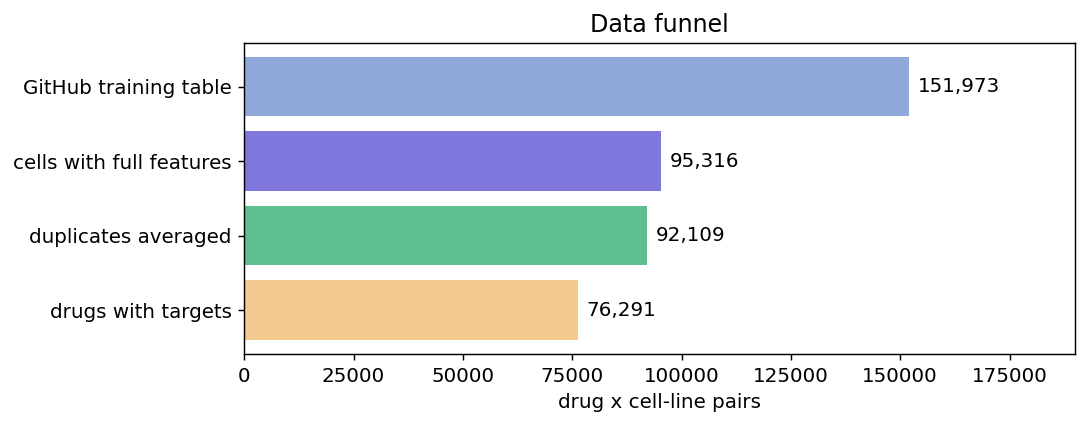

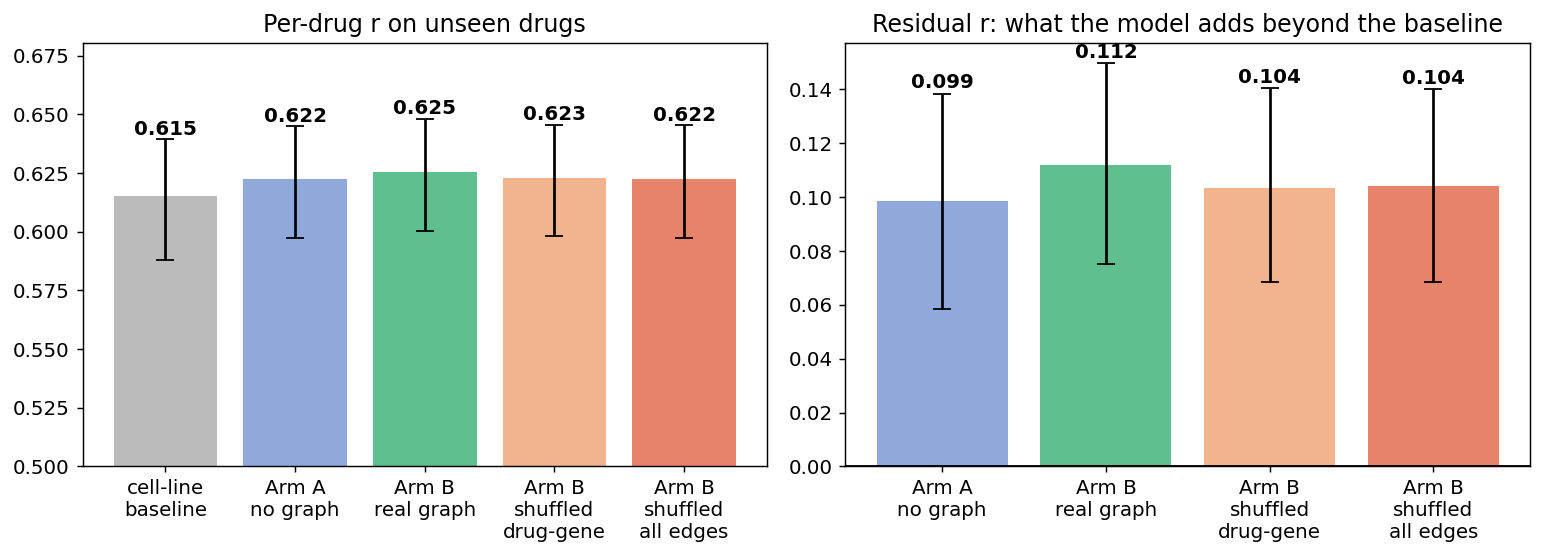

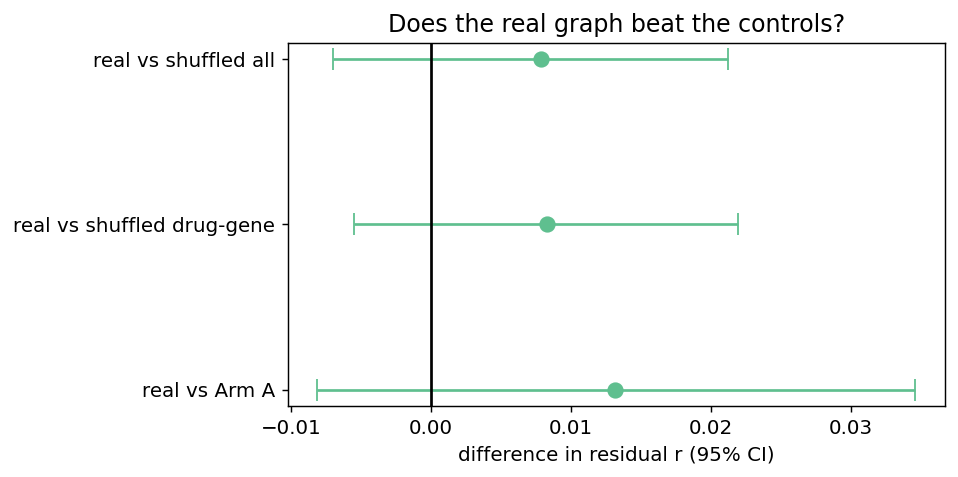

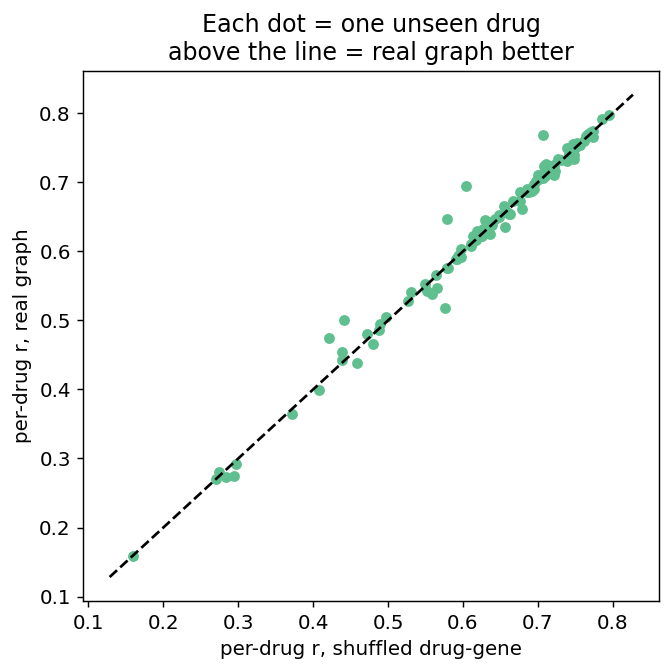

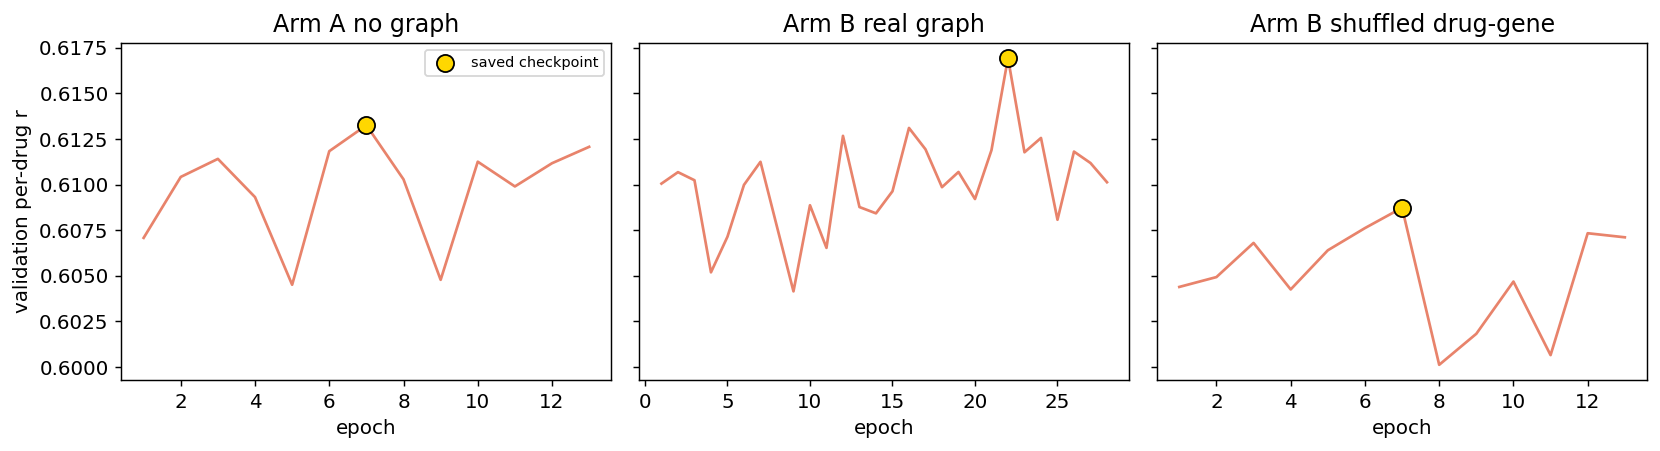

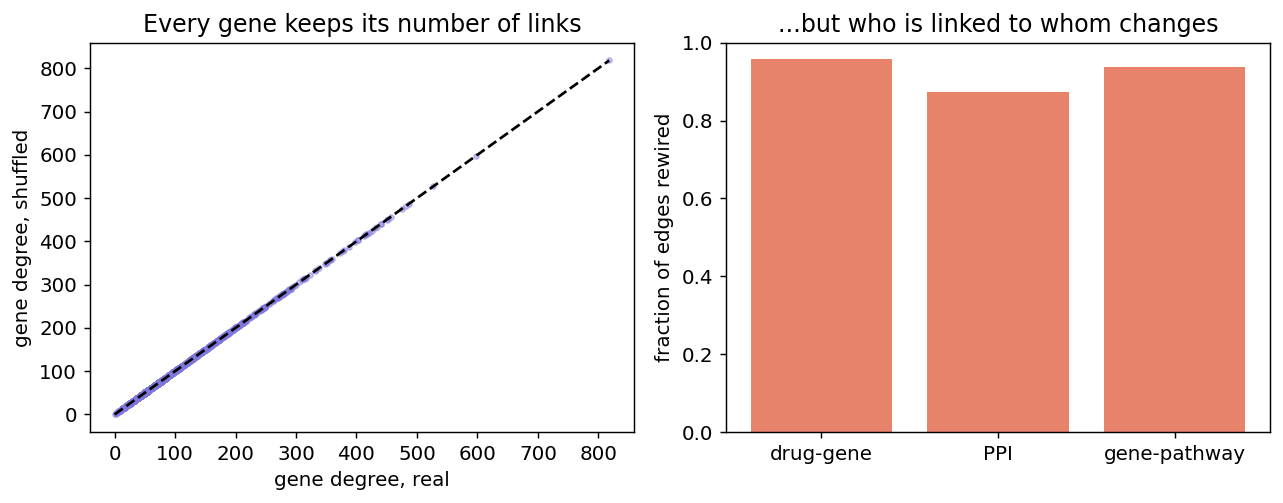

figures in /kaggle/working/figs/ ['fig1_funnel.png', 'fig2_main_result.png', 'fig3_paired.png', 'fig6_shuffle_proof.png', 'fig4_per_drug.png', 'fig5_training_curves.png']


In [7]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
plt.rcParams.update({"figure.dpi": 130, "font.size": 11})
R = json.load(open(RES)); DEVF = {f"fold{i}" for i in range(5)}
COL = {"BASE":"#BBBBBB","A":"#8FA9DB","B_real":"#5FBF8F","B_shuf_dg":"#F2B38F","B_shuf_all":"#E8836B"}
NM = {"BASE":"cell-line\nbaseline","A":"Arm A\nno graph","B_real":"Arm B\nreal graph","B_shuf_dg":"Arm B\nshuffled\ndrug-gene","B_shuf_all":"Arm B\nshuffled\nall edges"}

def collect(arm, folds, metric):
    acc = {}
    for k, v in R.items():
        a, fo, s = k.split("|")
        if a == arm and fo in folds:
            for d, x in v[metric].items(): acc.setdefault(int(d), []).append(x)
    return {d: float(np.mean(x)) for d, x in acc.items()}
def paired(x, y, folds, metric, nb=5000):
    a, b = collect(x, folds, metric), collect(y, folds, metric); ds = [d for d in a if d in b]
    if len(ds) < 10: return None
    diff = np.array([a[d] - b[d] for d in ds]); g = np.random.default_rng(0)
    bs = [g.choice(diff, len(diff)).mean() for _ in range(nb)]; lo, hi = np.percentile(bs, [2.5, 97.5])
    return diff.mean(), lo, hi, len(ds), wilcoxon(diff).pvalue
def report(folds, tag):
    print(f"\n===== {tag} =====")
    for metric, nmx in [("resid", "RESIDUAL per-drug r (what the model added beyond the cell baseline)"), ("per_drug", "per-drug r")]:
        print(nmx)
        for arm in ["BASE","A","B_real","B_shuf_dg","B_shuf_all"]:
            c = collect(arm, folds, metric)
            if c: print(f"   {arm:11s} mean {np.mean(list(c.values())):+.4f}  (n drugs {len(c)})")
        for x, y in [("B_real","A"),("B_real","B_shuf_dg"),("B_real","B_shuf_all")]:
            r = paired(x, y, folds, metric)
            if r: print(f"   {x} - {y}: {r[0]:+.4f} [95% CI {r[1]:+.4f}, {r[2]:+.4f}] n={r[3]} Wilcoxon p={r[4]:.3g}")
report(DEVF, "DEVELOPMENT (112 drugs)")

# FIG 1: funnel
fig, ax = plt.subplots(figsize=(8.5, 3.4)); st = [("GitHub training table", n_raw), ("cells with full features", n_feat), ("duplicates averaged", n_avg), ("drugs with targets", len(df))]
for i, (l, v) in enumerate(st): ax.barh(i, v, color=["#8FA9DB","#7F77DD","#5FBF8F","#F2C98F"][i]); ax.text(v+2000, i, f"{v:,}", va="center")
ax.set_yticks(range(4)); ax.set_yticklabels([s[0] for s in st]); ax.invert_yaxis(); ax.set_xlim(0, 190000); ax.set_xlabel("drug x cell-line pairs"); ax.set_title("Data funnel")
plt.tight_layout(); plt.savefig(FIG + "fig1_funnel.png"); plt.show()

# FIG 2: main result (bars with bootstrap CI over drugs)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, metric, arms, ttl in [(axs[0], "per_drug", ["BASE","A","B_real","B_shuf_dg","B_shuf_all"], "Per-drug r on unseen drugs"),
                              (axs[1], "resid", ["A","B_real","B_shuf_dg","B_shuf_all"], "Residual r: what the model adds beyond the baseline")]:
    for i, a in enumerate(arms):
        c = np.array(list(collect(a, DEVF, metric).values()))
        if len(c) == 0: continue
        g = np.random.default_rng(0); bs = [g.choice(c, len(c)).mean() for _ in range(2000)]; lo, hi = np.percentile(bs, [2.5, 97.5])
        ax.bar(i, c.mean(), color=COL[a], yerr=[[c.mean()-lo],[hi-c.mean()]], capsize=5); ax.text(i, hi + .002, f"{c.mean():.3f}", ha="center", fontweight="bold")
    ax.set_xticks(range(len(arms))); ax.set_xticklabels([NM[a] for a in arms]); ax.set_title(ttl)
    if metric == "resid": ax.axhline(0, color="k", lw=1)
    else: ax.set_ylim(0.5, None)
plt.tight_layout(); plt.savefig(FIG + "fig2_main_result.png"); plt.show()

# FIG 3: paired differences (CI that excludes 0 = real effect)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for i, (x, y) in enumerate([("B_real","A"),("B_real","B_shuf_dg"),("B_real","B_shuf_all")]):
    r = paired(x, y, DEVF, "resid")
    if r: ax.errorbar(r[0], i, xerr=[[r[0]-r[1]],[r[2]-r[0]]], fmt="o", capsize=6, color="#5FBF8F", ms=8)
ax.axvline(0, color="k"); ax.set_yticks(range(3)); ax.set_yticklabels(["real vs Arm A","real vs shuffled drug-gene","real vs shuffled all"])
ax.set_xlabel("difference in residual r (95% CI)"); ax.set_title("Does the real graph beat the controls?")
plt.tight_layout(); plt.savefig(FIG + "fig3_paired.png"); plt.show()

# FIG 4: per drug, real vs shuffled
a, b = collect("B_real", DEVF, "per_drug"), collect("B_shuf_dg", DEVF, "per_drug"); ds = [d for d in a if d in b]
if ds:
    fig, ax = plt.subplots(figsize=(5.3, 5.3)); xs, ys = [b[d] for d in ds], [a[d] for d in ds]
    ax.scatter(xs, ys, s=25, color="#5FBF8F"); lim = [min(xs+ys)-.03, max(xs+ys)+.03]; ax.plot(lim, lim, "k--")
    ax.set_xlabel("per-drug r, shuffled drug-gene"); ax.set_ylabel("per-drug r, real graph"); ax.set_title("Each dot = one unseen drug\nabove the line = real graph better")
    plt.tight_layout(); plt.savefig(FIG + "fig4_per_drug.png"); plt.show()

# FIG 5: training curves (fold 0, seed 0) with the saved-checkpoint dot
ta = [a for a in ["A","B_real","B_shuf_dg"] if f"{a}|fold0|seed0" in R]
fig, axs = plt.subplots(1, len(ta), figsize=(4.3*len(ta), 3.6), sharey=True); axs = np.atleast_1d(axs)
for ax, a in zip(axs, ta):
    h = R[f"{a}|fold0|seed0"]["history"]; v = [x["val_r"] for x in h]; ax.plot([x["epoch"] for x in h], v, color="#E8836B")
    bi = int(np.argmax(v)); ax.scatter(bi+1, v[bi], s=90, color="gold", edgecolor="k", zorder=5, label="saved checkpoint"); ax.set_title(NM[a].replace("\n"," ")); ax.set_xlabel("epoch")
axs[0].set_ylabel("validation per-drug r"); axs[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG + "fig5_training_curves.png"); plt.show()

# FIG 6: shuffle proof
old, new = base["gg"], EDG[("B_shuf_all", 0)]["gg"] if ("B_shuf_all", 0) in EDG else shuffle_undirected(base["gg"], 0)
d0, d1 = np.bincount(old.ravel(), minlength=G), np.bincount(new.ravel(), minlength=G)
key = lambda a: set(map(tuple, a.T.tolist()))
ch = [1 - len(key(base[r]) & key(EDG[("B_shuf_all", 0)][r]))/base[r].shape[1] for r in ["dg","gg","gp"]] if ("B_shuf_all", 0) in EDG else [0,0,0]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].scatter(d0, d1, s=8, alpha=.4, color="#7F77DD"); axs[0].plot([0, d0.max()], [0, d0.max()], "k--"); axs[0].set_xlabel("gene degree, real"); axs[0].set_ylabel("gene degree, shuffled"); axs[0].set_title("Every gene keeps its number of links")
axs[1].bar(["drug-gene","PPI","gene-pathway"], ch, color="#E8836B"); axs[1].set_ylim(0, 1); axs[1].set_ylabel("fraction of edges rewired"); axs[1].set_title("...but who is linked to whom changes")
plt.tight_layout(); plt.savefig(FIG + "fig6_shuffle_proof.png"); plt.show()
print("figures in", FIG, os.listdir(FIG))

In [8]:
import plotly.graph_objects as go
ent2sym = {v:k for k, v in json.load(open(IN + "sym2ent.json")).items()}
gname = lambda i: ent2sym.get(int(genes[i]), str(genes[i]))
cnt_t = pd.Series(base["dg"][0]).value_counts()
cand = [d for d in cnt_t.index if 2 <= cnt_t[d] <= 3]; d0_ = cand[0]
dname = drugs.DRUG_NAME[d0_]; print("drug shown:", dname)
SH = EDG[("B_shuf_all", 0)] if ("B_shuf_all", 0) in EDG else (get_M("B_shuf_all", 0) and EDG[("B_shuf_all", 0)])

def sub(e, rs=1):
    r = np.random.default_rng(rs); nodes, edges = {("D", d0_)}, []
    tg = [g for d, g in e["dg"].T if d == d0_]
    for g in tg: nodes.add(("G", g)); edges.append((("D", d0_), ("G", g)))
    for g in tg:
        nb = [b if a == g else a for a, b in e["gg"].T if g in (a, b)]
        for n_ in r.permutation(nb)[:5]: nodes.add(("G", n_)); edges.append((("G", g), ("G", n_)))
        pw = [p for gg_, p in e["gp"].T if gg_ == g]
        for p in r.permutation(pw)[:2]: nodes.add(("P", p)); edges.append((("G", g), ("P", p)))
    return nodes, edges
nr, er = sub(base); ns, es = sub(SH)
U = nx.Graph(); U.add_nodes_from(nr | ns); U.add_edges_from(er + es); pos_ = nx.spring_layout(U, seed=3, k=0.6)
rev_p = {i: p for p, i in pidx.items()}
def label(n):
    t, i = n
    return f"DRUG: {dname}" if t == "D" else (f"gene {gname(i)}" if t == "G" else f"pathway: {pname.get(rev_p[i], rev_p[i])[:40]}")
def edge_trace(E, color, vis):
    xs, ys = [], []
    for a, b in E: xs += [pos_[a][0], pos_[b][0], None]; ys += [pos_[a][1], pos_[b][1], None]
    return go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=1.6, color=color), hoverinfo="none", visible=vis, showlegend=False)
def node_trace(nodes, vis):
    cs = {"D": "#E8836B", "G": "#5FBF8F", "P": "#7F77DD"}; ss = {"D": 26, "G": 14, "P": 18}; nl = list(nodes)
    return go.Scatter(x=[pos_[n][0] for n in nl], y=[pos_[n][1] for n in nl], mode="markers", visible=vis, showlegend=False,
                      marker=dict(size=[ss[n[0]] for n in nl], color=[cs[n[0]] for n in nl], line=dict(width=1, color="white")),
                      text=[label(n) for n in nl], hoverinfo="text")
fig = go.Figure([edge_trace(er, "#5FBF8F", True), node_trace(nr, True), edge_trace(es, "#E8836B", False), node_trace(ns, False)])
fig.update_layout(title=f"What Arm B sees for {dname}: orange = drug, green = genes, purple = pathways",
    updatemenus=[dict(type="buttons", direction="right", x=0.5, y=1.12, xanchor="center", buttons=[
        dict(label="REAL biology graph", method="update", args=[{"visible": [True, True, False, False]}]),
        dict(label="SHUFFLED graph (same degrees)", method="update", args=[{"visible": [False, False, True, True]}])])],
    xaxis=dict(visible=False), yaxis=dict(visible=False), height=650, plot_bgcolor="white")
fig.write_html(OUT + "interactive_graph.html"); fig.show(); print("saved", OUT + "interactive_graph.html")

drug shown: Lenalidomide


saved /kaggle/working/interactive_graph.html


In [9]:
RUN_LOCKBOX = False      # set to True ONLY after committing this notebook to GitHub, then run once
if RUN_LOCKBOX:
    run_all(["A", "B_real", "B_shuf_dg", "B_shuf_all"], folds=["L"])
    report({"foldL"}, "LOCKBOX (30 drugs, tested once)")

In [10]:
import plotly.graph_objects as go
import networkx as nx, json, numpy as np, torch

ent2sym = {v: k for k, v in json.load(open(IN + "sym2ent.json")).items()}
gname = lambda i: ent2sym.get(int(genes[i]), str(genes[i]))
rev_p = {i: p for p, i in pidx.items()}

# trained real-graph model (fold 0, seed 0)
M = get_M("B_real", 0)
model = Net(G, True).to(dev); model.load_state_dict(torch.load(f"{CK}B_real_0_0.pt", map_location=dev)); model.eval()
trust = torch.softmax(model.rel_w, 0).detach().cpu().numpy()

# pick a drug from the fold-0 TEST set with 2-4 targets
te_drugs = {didx[x] for x in df.drug_id.values[ROLES[0][2]]}
cnt_t = pd.Series(base["dg"][0]).value_counts()
cand = [d for d in cnt_t.index if d in te_drugs and 2 <= cnt_t[d] <= 4] or [d for d in cnt_t.index if 2 <= cnt_t[d] <= 4]
d = cand[0]; dname = drugs.DRUG_NAME[d]; print("drug:", dname, "(unseen in training)" if d in te_drugs else "")

# 8 cell lines: 4 most sensitive, 4 most resistant for this drug
rows_ = df[df.drug_id == drugs.drug_id[d]].sort_values("label")
sel = pd.concat([rows_.head(4), rows_.tail(4)]); cidx = torch.tensor(sel.cell_line_id.map(cmap).values, device=dev)
tg = [int(g) for dd_, g in base["dg"].T if dd_ == d]
with torch.no_grad(): _, att = model(CELLX[cidx], torch.full((len(cidx),), d, device=dev), M, return_att=True)
att = att.cpu().numpy()[:, tg]                                   # [8 cells, n targets]

# subgraph: drug -> targets -> 8 PPI neighbours each -> 3 pathways each
r = np.random.default_rng(1); nodes = {("D", d)}; E_t, E_o = [], []
for g in tg:
    nodes.add(("G", g)); E_t.append((("D", d), ("G", g)))
    nb = [b if a == g else a for a, b in base["gg"].T if g in (a, b)]
    for n_ in r.permutation(nb)[:8]: nodes.add(("G", int(n_))); E_o.append((("G", g), ("G", int(n_))))
    for p in r.permutation([p for gg_, p in base["gp"].T if gg_ == g])[:3]: nodes.add(("P", int(p))); E_o.append((("G", g), ("P", int(p))))
U = nx.Graph(); U.add_edges_from(E_t + E_o); pos_ = nx.spring_layout(U, seed=4, k=0.55, iterations=200); nl = list(nodes)
SS = {"D": 32, "G": 13, "P": 17}
lab = lambda n: f"DRUG {dname}" if n[0] == "D" else (f"gene {gname(n[1])}" if n[0] == "G" else "pathway: " + str(pname.get(rev_p[n[1]], ""))[:45])

def xy(E):
    xs, ys = [], []
    for a, b in E: xs += [pos_[a][0], pos_[b][0], None]; ys += [pos_[a][1], pos_[b][1], None]
    return xs, ys
def colors(k):
    x = CELLX[cidx[k], :, 0].cpu().numpy(); return [x[n[1]] if n[0] == "G" else 0 for n in nl]
def texts(k):
    a = dict(zip([("G", g) for g in tg], att[k]))
    return [lab(n) + (f"<br>attention {a[n]:.0%}" if n in a else "") for n in nl]
def wid(k, j): return 2 + 26 * float(att[k, j])
tag = lambda k: f"{'SENSITIVE' if k < 4 else 'RESISTANT'} cell line {sel.CELL_LINE_NAME.iloc[k] if 'CELL_LINE_NAME' in sel else k}"

fig = go.Figure()
xs, ys = xy(E_o)
fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=0.8, color="#CCCCCC"), hoverinfo="none", showlegend=False))      # PPI / pathway lines
for j, e in enumerate(E_t):
    xs, ys = xy([e]); fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=wid(0, j), color="#E8836B"), hoverinfo="none", showlegend=False))
fig.add_trace(go.Scatter(x=[pos_[n][0] for n in nl], y=[pos_[n][1] for n in nl], mode="markers+text", textposition="top center",
    text=[gname(n[1]) if (n[0] == "G" and n[1] in tg) else (dname if n[0] == "D" else "") for n in nl], hovertext=texts(0), hoverinfo="text",
    marker=dict(size=[SS[n[0]] for n in nl], color=colors(0), cmin=-2, cmax=2, colorscale="RdBu_r", showscale=True,
                colorbar=dict(title="expression"), line=dict(width=1, color="black")), showlegend=False))
node_i = len(E_t) + 1
frames = [go.Frame(name=str(k), traces=list(range(1, len(E_t) + 1)) + [node_i],
    data=[go.Scatter(line=dict(width=wid(k, j), color="#E8836B")) for j in range(len(E_t))] +
         [go.Scatter(marker=dict(color=colors(k), cmin=-2, cmax=2, colorscale="RdBu_r", size=[SS[n[0]] for n in nl], line=dict(width=1, color="black")), hovertext=texts(k))])
    for k in range(len(cidx))]
fig.frames = frames
fig.update_layout(height=760, plot_bgcolor="white", xaxis=dict(visible=False), yaxis=dict(visible=False),
    title=f"Arm B on {dname}: thick orange line = high attention on that target | learned trust: own {trust[0]:.0%}, PPI {trust[1]:.0%}, pathway {trust[2]:.0%}",
    sliders=[dict(x=0.05, len=0.9, steps=[dict(label=tag(k), method="animate", args=[[str(k)], dict(mode="immediate", frame=dict(duration=500, redraw=True))]) for k in range(len(cidx))])],
    updatemenus=[dict(type="buttons", x=0.0, y=1.08, buttons=[dict(label="Play through cell lines", method="animate", args=[None, dict(frame=dict(duration=1500, redraw=True), fromcurrent=True)])])])
fig.write_html(OUT + "gnn_attention_diagram.html"); fig.show(); print("saved", OUT + "gnn_attention_diagram.html")

drug: Sorafenib (unseen in training)


saved /kaggle/working/gnn_attention_diagram.html


In [11]:
import plotly.graph_objects as go, networkx as nx, json, numpy as np, torch, pandas as pd
ent2sym = {v: k for k, v in json.load(open(IN + "sym2ent.json")).items()}
gname = lambda i: ent2sym.get(int(genes[i]), str(genes[i]))
rev_p = {i: p for p, i in pidx.items()}
cname = dict(zip(tt.cell_line_id, tt.CELL_LINE_NAME))

M = get_M("B_real", 0)
model = Net(G, True).to(dev); model.load_state_dict(torch.load(f"{CK}B_real_0_0.pt", map_location=dev)); model.eval()
trust = torch.softmax(model.rel_w, 0).detach().cpu().numpy()
te_drugs = sorted({didx[x] for x in df.drug_id.values[ROLES[0][2]]})
cnt_t = pd.Series(base["dg"][0]).value_counts()
cand = [d for d in te_drugs if d in cnt_t.index and 2 <= cnt_t[d] <= 5][:6]
print("drugs:", [drugs.DRUG_NAME[d] for d in cand], "| trust own/PPI/pathway:", trust.round(2))

gdeg = np.bincount(base["gg"].ravel(), minlength=G)
SS = {"D": 32, "G": 13, "P": 17}
def drug_fig(d):
    dname = drugs.DRUG_NAME[d]; r = np.random.default_rng(d)
    rows_ = df[df.drug_id == drugs.drug_id[d]].sort_values("label"); sel = pd.concat([rows_.head(4), rows_.tail(4)])
    cidx = torch.tensor(sel.cell_line_id.map(cmap).values, device=dev)
    tg = [int(g) for dd_, g in base["dg"].T if dd_ == d]
    with torch.no_grad(): _, att = model(CELLX[cidx], torch.full((len(cidx),), d, device=dev), M, return_att=True)
    att = att.cpu().numpy()[:, tg]
    nodes = {("D", d)}; E_t, E_o = [], []
    for g in tg:
        nodes.add(("G", g)); E_t.append((("D", d), ("G", g)))
        nb = [int(b if a == g else a) for a, b in base["gg"].T if g in (a, b)]
        for n_ in r.permutation(nb)[:10]: nodes.add(("G", n_)); E_o.append((("G", g), ("G", n_)))
        for p in r.permutation([int(p) for gg_, p in base["gp"].T if gg_ == g])[:3]: nodes.add(("P", p)); E_o.append((("G", g), ("P", p)))
    U = nx.Graph(); U.add_edges_from(E_t + E_o); pos_ = nx.spring_layout(U, seed=4, k=0.55, iterations=200); nl = list(nodes)
    lab = lambda n: f"DRUG {dname}" if n[0] == "D" else (f"gene {gname(n[1])} (degree {gdeg[n[1]]})" if n[0] == "G" else "pathway: " + str(pname.get(rev_p[n[1]], ""))[:50])
    def xy(E):
        xs, ys = [], []
        for a, b in E: xs += [pos_[a][0], pos_[b][0], None]; ys += [pos_[a][1], pos_[b][1], None]
        return xs, ys
    expr = lambda k: CELLX[cidx[k], :, 0].cpu().numpy()
    colors = lambda k: [expr(k)[n[1]] if n[0] == "G" else 0 for n in nl]
    def texts(k):
        a = dict(zip([("G", g) for g in tg], att[k]))
        return [lab(n) + (f"<br><b>attention {a[n]:.0%}</b>" if n in a else "") + (f"<br>expression {expr(k)[n[1]]:+.2f}" if n[0] == "G" else "") for n in nl]
    tag = lambda k: f"{'SENSITIVE' if k < 4 else 'RESISTANT'}: {cname.get(sel.cell_line_id.iloc[k], '')} (LN_IC50 {sel.label.iloc[k]:.1f})"
    fig = go.Figure(); xs, ys = xy(E_o)
    fig.add_trace(go.Scattergl(x=xs, y=ys, mode="lines", line=dict(width=0.8, color="#CCCCCC"), hoverinfo="none", showlegend=False))
    for j, e in enumerate(E_t):
        xs, ys = xy([e]); fig.add_trace(go.Scatter(x=xs, y=ys, mode="lines", line=dict(width=2 + 26 * float(att[0, j]), color="#E8836B"), hoverinfo="none", showlegend=False))
    fig.add_trace(go.Scatter(x=[pos_[n][0] for n in nl], y=[pos_[n][1] for n in nl], mode="markers+text", textposition="top center",
        text=[gname(n[1]) if (n[0] == "G" and n[1] in tg) else (dname if n[0] == "D" else "") for n in nl], hovertext=texts(0), hoverinfo="text",
        marker=dict(size=[SS[n[0]] for n in nl], color=colors(0), cmin=-2, cmax=2, colorscale="RdBu_r", showscale=True, colorbar=dict(title="expression"), line=dict(width=1, color="black")), showlegend=False))
    ni = len(E_t) + 1
    fig.frames = [go.Frame(name=str(k), traces=list(range(1, ni)) + [ni],
        data=[go.Scatter(line=dict(width=2 + 26 * float(att[k, j]), color="#E8836B")) for j in range(len(E_t))] +
             [go.Scatter(marker=dict(color=colors(k), cmin=-2, cmax=2, colorscale="RdBu_r", size=[SS[n[0]] for n in nl], line=dict(width=1, color="black")), hovertext=texts(k))],
        layout=dict(title_text=f"{dname} | {tag(k)} | thick orange = high attention on that target")) for k in range(len(cidx))]
    fig.update_layout(height=760, plot_bgcolor="white", xaxis=dict(visible=False), yaxis=dict(visible=False), dragmode="pan",
        title=f"{dname} | {tag(0)} | thick orange = high attention on that target",
        sliders=[dict(x=0.05, len=0.9, steps=[dict(label=("S" if k < 4 else "R") + str(k % 4 + 1), method="animate", args=[[str(k)], dict(mode="immediate", frame=dict(duration=400, redraw=True), transition=dict(duration=0))]) for k in range(len(cidx))])],
        updatemenus=[dict(type="buttons", x=0.0, y=1.08, buttons=[dict(label="Play", method="animate", args=[None, dict(frame=dict(duration=1400, redraw=True), fromcurrent=True)])])])
    return fig

# ---- big hairball: all targets of the unseen drugs, 10 neighbours each, drugs in orange
r = np.random.default_rng(7); tgs = sorted({int(g) for d in te_drugs for dd_, g in base["dg"].T if dd_ == d})
nb_of = {g: [int(b if a == g else a) for a, b in base["gg"].T if g in (a, b)] for g in tgs}
Eb, nodesb = [], set(("G", g) for g in tgs)
for g in tgs:
    for n_ in r.permutation(nb_of[g])[:10]: nodesb.add(("G", n_)); Eb.append((("G", g), ("G", n_)))
for d in te_drugs:
    nodesb.add(("D", d))
    for dd_, g in base["dg"].T:
        if dd_ == d: Eb.append((("D", d), ("G", int(g))))
Ub = nx.Graph(); Ub.add_edges_from(Eb); pb = nx.spring_layout(Ub, seed=2, k=0.12, iterations=120); nlb = [n for n in nodesb if n in pb]
dg_of = {}
for dd_, g in base["dg"].T: dg_of.setdefault(int(g), []).append(drugs.DRUG_NAME[dd_])
xs, ys = [], []
for a, b in Eb:
    if a in pb and b in pb: xs += [pb[a][0], pb[b][0], None]; ys += [pb[a][1], pb[b][1], None]
big = go.Figure()
big.add_trace(go.Scattergl(x=xs, y=ys, mode="lines", line=dict(width=0.5, color="#CCCCCC"), hoverinfo="none", showlegend=False))
big.add_trace(go.Scattergl(x=[pb[n][0] for n in nlb], y=[pb[n][1] for n in nlb], mode="markers", showlegend=False, hoverinfo="text",
    text=[(f"DRUG {drugs.DRUG_NAME[n[1]]}" if n[0] == "D" else f"gene {gname(n[1])} | degree {gdeg[n[1]]}" + (f"<br>target of: {', '.join(dg_of[n[1]][:6])}" if n[1] in dg_of else "")) for n in nlb],
    marker=dict(size=[16 if n[0] == "D" else (9 if n[1] in dg_of else 5) for n in nlb], color=["#E8836B" if n[0] == "D" else ("#7F77DD" if n[1] in dg_of else "#5FBF8F") for n in nlb], line=dict(width=0.5, color="white"))))
big.update_layout(height=800, plot_bgcolor="white", xaxis=dict(visible=False), yaxis=dict(visible=False), dragmode="pan",
    title="Whole neighbourhood: orange = unseen drugs, purple = target genes, green = their PPI neighbours (scroll to zoom, hover for names)")

figs = [drug_fig(d) for d in cand]; names = [drugs.DRUG_NAME[d] for d in cand]
parts = [f'<div id="d{i}" style="display:{"block" if i == 0 else "none"}">' + f.to_html(full_html=False, include_plotlyjs=("cdn" if i == 0 else False), div_id=f"pd{i}", auto_play=False, config=dict(scrollZoom=True)) + "</div>" for i, f in enumerate(figs)]
parts.append('<div id="big" style="display:none">' + big.to_html(full_html=False, include_plotlyjs=False, div_id="pbig", config=dict(scrollZoom=True)) + "</div>")
opts = "".join(f'<option value="{i}">{n}</option>' for i, n in enumerate(names)) + '<option value="big">WHOLE NETWORK (zoomable)</option>'
js = """<script>function sw(v){var ids=[%s,'big'];ids.forEach(function(k){var e=document.getElementById(k=='big'?'big':'d'+k);e.style.display=(String(k)==v)?'block':'none';});window.dispatchEvent(new Event('resize'));}</script>""" % ",".join(str(i) for i in range(len(cand)))
html = f"<html><body style='font-family:sans-serif'><h2>Arm B: attention on target genes, real trained model</h2>Pick view: <select onchange='sw(this.value)' style='font-size:16px;padding:6px'>{opts}</select> &nbsp; learned trust: own signal {trust[0]:.0%}, PPI {trust[1]:.0%}, pathway {trust[2]:.0%}{''.join(parts)}{js}</body></html>"
open(OUT + "gnn_full_explorer.html", "w").write(html); print("saved", OUT + "gnn_full_explorer.html")

drugs: ['SB216763', 'PD173074', 'Sorafenib', 'Rucaparib', 'AZ960', 'Ruxolitinib'] | trust own/PPI/pathway: [0.45 0.28 0.27]
saved /kaggle/working/gnn_full_explorer.html
